1 — Import Library

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.utils import resample

2 — Load Dataset Sebelum Balancing

In [ ]:
from google.colab import files

uploaded = files.upload()
df = pd.read_csv("dataset_setelah_tambah_C4_sebelum_balancing.csv")
df.head()

Saving dataset_setelah_tambah_C4_sebelum_balancing.csv to dataset_setelah_tambah_C4_sebelum_balancing.csv


,No,Komentar,Label Awal,Label Pakar,Pasal Dominan,Catatan,Unnamed: 6,Kode Label,jumlah_kata,jumlah_karakter,clean_comment
0,1.0,anu boga modal mah bulak balik jadi anggota dp...,Kritik atau opini negatif,Kritik atau opini negatif,NaN,Tidak terindikasi Pasal 27A maupun Pasal 28 ay...,NaN,C1,32.0,174.0,anu boga modal mah bulak balik jadi anggota dp...
1,2.0,Para pejabat seperti ini yg dipelihara di nega...,Kritik atau opini negatif,Kritik atau opini negatif,NaN,Tidak terindikasi Pasal 27A maupun Pasal 28 ay...,NaN,C1,63.0,402.0,para pejabat seperti ini yg dipelihara di nega...
2,3.0,Sepaham kita,Netral atau tidak terindikasi,NaN,NaN,NaN,NaN,NaN,2.0,12.0,sepaham kita
3,4.0,kasus klasik. Pejabat suku jawa bersatu padu m...,Kritik atau opini negatif,Kritik atau opini negatif,NaN,Tidak terindikasi Pasal 27A maupun Pasal 28 ay...,NaN,C1,39.0,236.0,kasus klasik. pejabat suku jawa bersatu padu m...
4,5.0,"Kalo di olahraga kaderisasinya jelas, ada anak...",Konten ofensif,Kritik atau opini negatif,NaN,Tidak terindikasi Pasal 27A maupun Pasal 28 ay...,NaN,C1,81.0,533.0,"kalo di olahraga kaderisasinya jelas, ada anak..."


3 — Pemeriksaan Awal Dataset

In [ ]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8218 entries, 0 to 8217
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   No               8000 non-null   float64
 1   Komentar         8218 non-null   object 
 2   Label Awal       8218 non-null   object 
 3   Label Pakar      8215 non-null   object 
 4   Pasal Dominan    642 non-null    object 
 5   Catatan          7212 non-null   object 
 6   Unnamed: 6       2 non-null      object 
 7   Kode Label       8215 non-null   object 
 8   jumlah_kata      8000 non-null   float64
 9   jumlah_karakter  8000 non-null   float64
 10  clean_comment    8218 non-null   object 
dtypes: float64(3), object(8)
memory usage: 706.4+ KB


4 — Melihat Distribusi Awal Kelas

In [ ]:
distribusi_awal = (df["Kode Label"].value_counts().sort_index())
distribusi_awal

,count
Kode Label,
C0,2226
C1,3012
C2,1451
C3,763
C4,763


5 — Pemeriksaan Nilai Kosong

In [ ]:
df.isnull().sum()

,0
No,218
Komentar,0
Label Awal,0
Label Pakar,3
Pasal Dominan,7576
Catatan,1006
Unnamed: 6,8216
Kode Label,3
jumlah_kata,218
jumlah_karakter,218


6 — Pemeriksaan Label Kosong

In [ ]:
jumlah_label_kosong = (df["Kode Label"].isnull().sum())
print("Jumlah data tanpa kode label:",jumlah_label_kosong)

Jumlah data tanpa kode label: 3


7 — Melihat Data dengan Label Kosong

In [ ]:
df[df["Kode Label"].isnull()]

,No,Komentar,Label Awal,Label Pakar,Pasal Dominan,Catatan,Unnamed: 6,Kode Label,jumlah_kata,jumlah_karakter,clean_comment
2,3.0,Sepaham kita,Netral atau tidak terindikasi,NaN,NaN,NaN,NaN,NaN,2.0,12.0,sepaham kita
1135,1136.0,Betul se x hanya kepntinga partai dn kroni,Konten ofensif,NaN,NaN,NaN,NaN,NaN,8.0,42.0,betul se x hanya kepntinga partai dn kroni
2517,2518.0,"Pigai ngawur sj,bukan kls kamu debat dg roki",Kritik atau opini negatif,NaN,NaN,catatan disusun berdasarkan isi komentar dan p...,NaN,NaN,8.0,44.0,"pigai ngawur sj,bukan kls kamu debat dg roki"


8 — Menghapus Data Tanpa Label

In [ ]:
df = df.dropna(subset=["Kode Label"])
print("Jumlah data setelah menghapus label kosong:",len(df))

Jumlah data setelah menghapus label kosong: 8215


9 — Validasi Kode Label

In [ ]:
df["Kode Label"].unique()

array(['C1', 'C4', 'C2', 'C0', 'C3'], dtype=object)

10 — Distribusi Dataset Sebelum Balancing

In [ ]:
distribusi_awal = (df["Kode Label"].value_counts().sort_index())
distribusi_awal

,count
Kode Label,
C0,2226
C1,3012
C2,1451
C3,763
C4,763


11 — Visualisasi Distribusi Awal

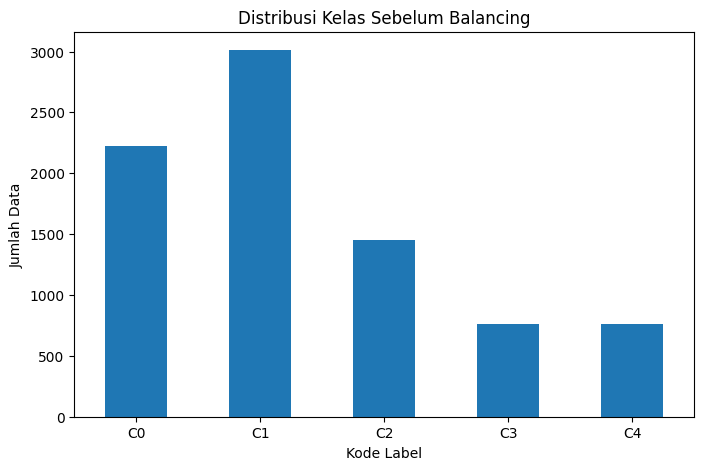

In [ ]:
plt.figure(figsize=(8,5))

distribusi_awal.plot(kind="bar")
plt.title("Distribusi Kelas Sebelum Balancing")
plt.xlabel("Kode Label")
plt.ylabel("Jumlah Data")

plt.xticks(rotation=0)
plt.show()

12 — Menentukan Target Balancing

In [ ]:
target_balancing = (df["Kode Label"].value_counts().min())
print("Target jumlah setiap kelas:",target_balancing)

Target jumlah setiap kelas: 763


13 — Melakukan Undersampling

In [ ]:
df_balanced = pd.DataFrame()

for label in df["Kode Label"].unique():
    df_label = df[df["Kode Label"] == label]

    df_sample = resample(
        df_label,
        replace=False,
        n_samples=target_balancing,
        random_state=42)

    df_balanced = pd.concat([df_balanced,df_sample],ignore_index=True)

14 — Mengacak Dataset Balanced

In [ ]:
df_balanced = (
    df_balanced
    .sample(
        frac=1,
        random_state=42
    ).reset_index(drop=True))

15 — Validasi Distribusi Setelah Balancing

In [ ]:
distribusi_akhir = (df_balanced["Kode Label"].value_counts().sort_index())
distribusi_akhir

,count
Kode Label,
C0,763
C1,763
C2,763
C3,763
C4,763


16 — Visualisasi Dataset Balanced

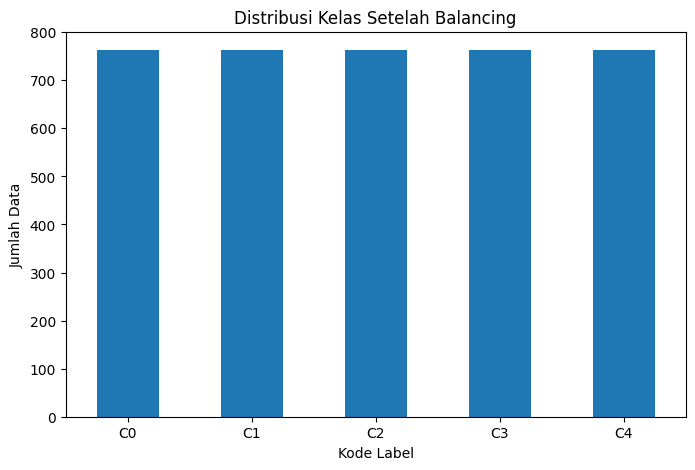

In [ ]:
plt.figure(figsize=(8,5))

distribusi_akhir.plot(kind="bar")
plt.title("Distribusi Kelas Setelah Balancing")
plt.xlabel("Kode Label")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=0)

plt.show()

17 — Perbandingan Jumlah Dataset

In [ ]:
print("Jumlah data sebelum balancing:",len(df))
print("Jumlah data setelah balancing:",len(df_balanced))

Jumlah data sebelum balancing: 8215
Jumlah data setelah balancing: 3815


18 — Simpan Dataset Balanced

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df_balanced.to_csv("/content/drive/MyDrive/Bimbingan_27-08/dataset_balanced_C0-C4.csv",index=False)

print("Dataset balanced berhasil disimpan")

Dataset balanced berhasil disimpan


19 — Preview Dataset Final

In [ ]:
df_balanced.head()

,No,Komentar,Label Awal,Label Pakar,Pasal Dominan,Catatan,Unnamed: 6,Kode Label,jumlah_kata,jumlah_karakter,clean_comment
0,5708.0,Apakah seorang maling anak'y jg akan menjadi m...,Indikasi penghinaan atau kebencian terhadap in...,Ambigu atau konteks tidak cukup,NaN,Pertanyaan umum tanpa target yang jelas.,NaN,C4,8.0,56.0,apakah seorang maling anak'y jg akan menjadi m...
1,495.0,"​@HanaFanda-wx1cciyaa betul,\nMeni hese ngesah...",Netral atau tidak terindikasi,Konten ofensif,NaN,Tidak terindikasi Pasal 27A maupun Pasal 28 ay...,NaN,C2,12.0,91.0,"​@hanafanda-wx1cciyaa betul, meni hese ngesahk..."
2,1841.0,Omongan nya pak bahlil sering kontradiksi. Lah...,Netral atau tidak terindikasi,Netral atau tidak terindikasi,NaN,NaN,NaN,C0,7.0,50.0,omongan nya pak bahlil sering kontradiksi. lah...
3,6483.0,Astagfirullah. Katanya Wakil Rakyat tapi kelak...,Indikasi penghinaan atau kebencian terhadap in...,Konten ofensif,NaN,Menuduh wakil rakyat sebagai maling dan zalim.,NaN,C2,13.0,96.0,astagfirullah. katanya wakil rakyat tapi kelak...
4,2222.0,"Cobalah pampang ke45 poin itu di media sosial,...",Netral atau tidak terindikasi,Ambigu atau konteks tidak cukup,NaN,komentar ini belum menunjukkan unsur yang cuku...,NaN,C4,12.0,76.0,"cobalah pampang ke45 poin itu di media sosial,..."


In [ ]:
# CEK PANJANG KATA C3 DAN C4 SETELAH BALANCING

import re
import pandas as pd
import matplotlib.pyplot as plt

# Ambil C3 dan C4
df_c34 = df_balanced[
    df_balanced["Kode Label"].isin(["C3", "C4"])
].copy()

# Fungsi menghitung jumlah kata
def hitung_jumlah_kata(teks):
    if pd.isna(teks):
        return 0
    return len(re.findall(r"\b\w+\b", str(teks)))

# Hitung panjang komentar
df_c34["Jumlah_Kata"] = df_c34["Komentar"].apply(
    hitung_jumlah_kata
)

# Statistik per kelas
statistik_c34 = (
    df_c34
    .groupby("Kode Label")["Jumlah_Kata"]
    .agg(
        Jumlah_Data="count",
        Minimum="min",
        Q1=lambda x: x.quantile(0.25),
        Median="median",
        Mean="mean",
        Q3=lambda x: x.quantile(0.75),
        Maksimum="max"
    )
    .round(2)
)

display(statistik_c34)

,Jumlah_Data,Minimum,Q1,Median,Mean,Q3,Maksimum
Kode Label,,,,,,,
C3,763,2,12.5,22.0,38.63,41.0,705
C4,763,0,4.0,8.0,11.02,15.0,113


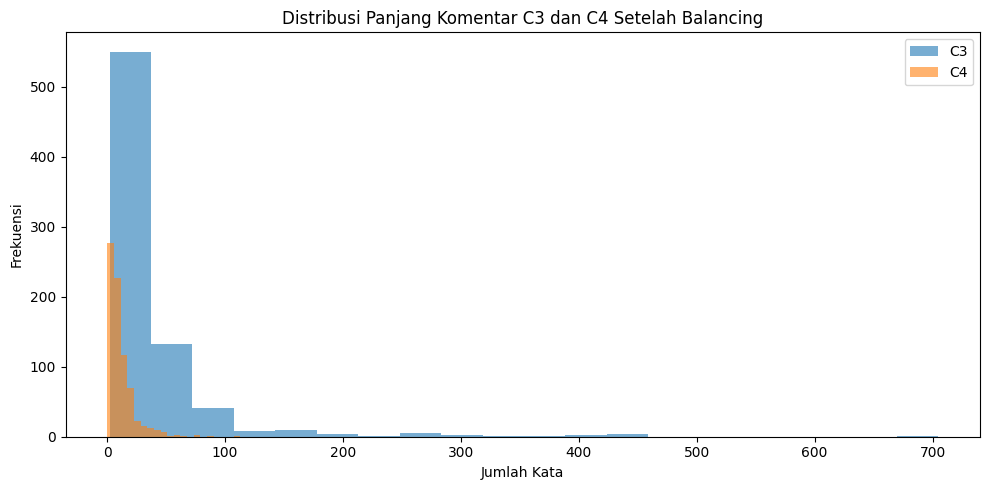

In [ ]:
# DISTRIBUSI PANJANG KOMENTAR C3 DAN C4

plt.figure(figsize=(10, 5))

plt.hist(
    df_c34.loc[
        df_c34["Kode Label"] == "C3",
        "Jumlah_Kata"
    ],
    bins=20,
    alpha=0.6,
    label="C3"
)

plt.hist(
    df_c34.loc[
        df_c34["Kode Label"] == "C4",
        "Jumlah_Kata"
    ],
    bins=20,
    alpha=0.6,
    label="C4"
)

plt.xlabel("Jumlah Kata")
plt.ylabel("Frekuensi")
plt.title("Distribusi Panjang Komentar C3 dan C4 Setelah Balancing")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# KATEGORI PANJANG KOMENTAR
# ==========================================

def kategori_panjang(jumlah):
    if jumlah <= 5:
        return "1–5 kata"
    elif jumlah <= 10:
        return "6–10 kata"
    elif jumlah <= 20:
        return "11–20 kata"
    else:
        return ">20 kata"


df_c34["Kategori_Panjang"] = (
    df_c34["Jumlah_Kata"]
    .apply(kategori_panjang)
)

distribusi_panjang_c34 = pd.crosstab(
    df_c34["Kategori_Panjang"],
    df_c34["Kode Label"]
)

urutan = [
    "1–5 kata",
    "6–10 kata",
    "11–20 kata",
    ">20 kata"
]

distribusi_panjang_c34 = (
    distribusi_panjang_c34
    .reindex(urutan, fill_value=0)
)

display(distribusi_panjang_c34)

Kode Label,C3,C4
Kategori_Panjang,,
1–5 kata,38,276
6–10 kata,110,202
11–20 kata,211,191
>20 kata,404,94


In [ ]:
# CEK PANJANG KATA C0-C4 SETELAH BALANCING

import re
import pandas as pd
import matplotlib.pyplot as plt

df_panjang = df_balanced.copy()

# Fungsi menghitung jumlah kata
def hitung_jumlah_kata(teks):
    if pd.isna(teks):
        return 0
    return len(re.findall(r"\b\w+\b", str(teks)))

# Hitung jumlah kata dari komentar asli
df_panjang["Jumlah_Kata"] = (
    df_panjang["Komentar"]
    .apply(hitung_jumlah_kata)
)

# Statistik panjang komentar per kelas
statistik_panjang = (
    df_panjang
    .groupby("Kode Label")["Jumlah_Kata"]
    .agg(
        Jumlah_Data="count",
        Minimum="min",
        Q1=lambda x: x.quantile(0.25),
        Median="median",
        Mean="mean",
        Q3=lambda x: x.quantile(0.75),
        Maksimum="max"
    )
    .round(2)
)

display(statistik_panjang)

,Jumlah_Data,Minimum,Q1,Median,Mean,Q3,Maksimum
Kode Label,,,,,,,
C0,763,0,7.0,14.0,20.62,25.5,297
C1,763,1,11.5,20.0,29.70,35.0,449
C2,763,1,8.0,15.0,22.81,25.0,421
C3,763,2,12.5,22.0,38.63,41.0,705
C4,763,0,4.0,8.0,11.02,15.0,113


In [ ]:
# DISTRIBUSI KATEGORI PANJANG C0-C4

def kategori_panjang(jumlah):
    if jumlah <= 5:
        return "1–5 kata"
    elif jumlah <= 10:
        return "6–10 kata"
    elif jumlah <= 20:
        return "11–20 kata"
    else:
        return ">20 kata"


df_panjang["Kategori_Panjang"] = (
    df_panjang["Jumlah_Kata"]
    .apply(kategori_panjang)
)

distribusi_panjang = pd.crosstab(
    df_panjang["Kategori_Panjang"],
    df_panjang["Kode Label"]
)

urutan_kategori = [
    "1–5 kata",
    "6–10 kata",
    "11–20 kata",
    ">20 kata"
]

distribusi_panjang = (
    distribusi_panjang
    .reindex(urutan_kategori, fill_value=0)
    .reindex(columns=["C0", "C1", "C2", "C3", "C4"], fill_value=0)
)

display(distribusi_panjang)

Kode Label,C0,C1,C2,C3,C4
Kategori_Panjang,,,,,
1–5 kata,130,47,89,38,276
6–10 kata,163,122,173,110,202
11–20 kata,215,227,226,211,191
>20 kata,255,367,275,404,94


In [ ]:
# PERSENTASE DISTRIBUSI PANJANG C0-C4

persentase_panjang = (
    distribusi_panjang
    .div(distribusi_panjang.sum(axis=0), axis=1)
    * 100
).round(2)

display(persentase_panjang)

Kode Label,C0,C1,C2,C3,C4
Kategori_Panjang,,,,,
1–5 kata,17.04,6.16,11.66,4.98,36.17
6–10 kata,21.36,15.99,22.67,14.42,26.47
11–20 kata,28.18,29.75,29.62,27.65,25.03
>20 kata,33.42,48.10,36.04,52.95,12.32
